# Cluster parishes and find comparable parishes

Use `data/04_extract_features/7_parish_features.csv` to cluster parishes with KMeans and retrieve the ten nearest reference parishes **within the assigned cluster** for every parish in `TARGET_DIOCESE`. Set the target diocese in section 0. Run from the project root. Outputs belong in `data/05_cluster_parishes/`.

Similarity describes county context, homepage social linking, and predicted school affiliation. These features do not measure parish attendance or ministry quality. County values are shared by parishes in the same county, so identical feature vectors and zero-distance ties are possible. The analysis retains all target parishes and flags matches based on imputed target features as provisional.


## 0 Setup and analysis settings

Install project dependencies with `%pip install -e .` if needed. Use a fixed random seed and 20 KMeans initializations, then repeat each candidate cluster count across five seeds to check stability. No website downloads or LLM calls are made here.


In [1]:
import hashlib
import json
import pickle
import platform
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples
from threadpoolctl import threadpool_limits

from utils.clustering import (
    FEATURES, MODEL_FEATURES, cluster_profiles, evaluate_kmeans,
    prepare_clustering_data, select_cluster_count, within_cluster_neighbors,
)

INPUT_PATH = Path("data/04_extract_features/7_parish_features.csv")
OUTPUT_DIR = Path("data/05_cluster_parishes")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TARGET_DIOCESE = "Diocese of Fort Wayne-South Bend"
TOP_N = 10
K_VALUES = list(range(2, 11))
SEEDS = [42, 7, 21, 83, 101]
N_INIT = 20
MIN_REFERENCE_CLUSTER_SIZE = 2 * (TOP_N + 1)  # Headroom beyond the ten requested peers.
MIN_STABILITY_ARI = 0.90
SILHOUETTE_TOLERANCE = 0.02

REQUESTED_K = None  # Automatic selection; set an integer for a reviewed override.


## 1 Load and inspect feature coverage

Read county codes as strings and school predictions as nullable booleans. Use only the four feature columns for clustering; parish names, dioceses, county identifiers, and prediction statuses are retained for interpretation and reporting. Report coverage by diocese so complete-case selection bias is visible.


In [2]:
parishes_df = pd.read_csv(
    INPUT_PATH, dtype={"county_fips": "string", "attached_school": "boolean"},
).reset_index(drop=True)
assert parishes_df["parish_index"].notna().all() and parishes_df["parish_index"].is_unique
assert parishes_df["diocese"].eq(TARGET_DIOCESE).any(), "Target diocese not found"

feature_coverage_df = parishes_df.groupby("diocese")[FEATURES].count()
feature_coverage_df.insert(0, "n_parishes", parishes_df.groupby("diocese").size())
feature_coverage_df["complete_records"] = (
    parishes_df[FEATURES].notna().all(axis=1).groupby(parishes_df["diocese"]).sum()
)
feature_coverage_df.to_csv(OUTPUT_DIR / "1_feature_coverage_by_diocese.csv")
print(f"Loaded {len(parishes_df)} parishes; {parishes_df['diocese'].eq(TARGET_DIOCESE).sum()} target parishes")
feature_coverage_df


Loaded 864 parishes; 80 target parishes


,n_parishes,county_population,county_median_age,n_social_links,attached_school,complete_records
diocese,,,,,,
Archdiocese of Anchorage-Juneau,53,51,51,37,37,37
Archdiocese of Indianapolis,132,132,132,109,109,109
Archdiocese of Mobile,86,85,85,67,67,66
Diocese of Birmingham,80,76,76,39,39,37
Diocese of Fairbanks,47,43,43,10,10,9
Diocese of Fort Wayne-South Bend,80,80,80,67,67,67
Diocese of Fresno,136,130,130,73,73,67
Diocese of Monterey,47,47,47,34,34,34
Diocese of Pensacola-Tallahassee,57,56,56,53,53,52


## 2 Prepare the model space

Fit KMeans and preprocessing on **complete records only**. This avoids building clusters around the many missing homepage/school observations. The complete-case reference pool can underrepresent dioceses with poor website coverage; retain the coverage table when interpreting results.

- Apply `log1p` to county population and social-link count to reduce skew.
- Standardize those two transformed variables and county median age to one standard deviation each.
- Encode school as 0/1 without scaling it by its minority-class variance. A school mismatch contributes one squared-distance unit; a one-standard-deviation difference in a continuous feature also contributes one.
- Learn continuous medians and the school mode from complete reference records. Use these values only when assigning partial records to the fitted clusters. Preserve the original values and the names of imputed features.

A partial target receives a provisional cluster and distances in this same imputed model space. Reference candidates for matching must have all four observed features. A parish missing every feature remains unassigned, with an explicit target-summary status if applicable. Unknown school/social values are never converted to observed false/zero.


In [3]:
model_input_df, model_matrix, reference_mask, input_quality_df, preprocessor = prepare_clustering_data(parishes_df)
reference_df = parishes_df.loc[reference_mask].copy()
reference_matrix = model_matrix[reference_mask.to_numpy()]
assignable_mask = input_quality_df["n_observed_features"].gt(0)

quality_export_df = parishes_df[["parish_index", "name", "diocese"]].merge(
    input_quality_df, on="parish_index", validate="one_to_one",
)
quality_export_df.to_csv(OUTPUT_DIR / "2_input_quality.csv", index=False)
matrix_export_df = pd.DataFrame(model_matrix, columns=MODEL_FEATURES)
matrix_export_df.insert(0, "parish_index", parishes_df["parish_index"])
matrix_export_df["is_reference"] = reference_mask
matrix_export_df["assignable"] = assignable_mask
matrix_export_df.to_csv(OUTPUT_DIR / "2_clustering_matrix.csv", index=False)
print(f"Fit/reference pool: {len(reference_df)} complete parishes")
print(f"Partial assignments: {(assignable_mask & ~reference_mask).sum()}; no-feature rows: {(~assignable_mask).sum()}")
quality_export_df.groupby("diocese").agg(
    n_parishes=("parish_index", "size"), n_reference=("is_reference", "sum"),
)


Fit/reference pool: 589 complete parishes
Partial assignments: 266; no-feature rows: 9


,n_parishes,n_reference
diocese,,
Archdiocese of Anchorage-Juneau,53,37
Archdiocese of Indianapolis,132,109
Archdiocese of Mobile,86,66
Diocese of Birmingham,80,37
Diocese of Fairbanks,47,9
Diocese of Fort Wayne-South Bend,80,67
Diocese of Fresno,136,67
Diocese of Monterey,47,34
Diocese of Pensacola-Tallahassee,57,52


## 3 Compare cluster counts and inspect candidate profiles

[Silhouette](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html) is higher for better separated assignments; the [Davies?Bouldin index](https://scikit-learn.org/stable/modules/clustering.html#davies-bouldin-index) is lower for better separation. Also inspect minimum cluster size and adjusted Rand agreement across seeds (1 means the same partition, up to label changes). Inertia is diagnostic only; it decreases as clusters are added.

Compare `k=2..10`. A practical shortlist requires at least 22 reference members in every cluster, mean seed agreement at least 0.90, and a silhouette within 0.02 of the best tested score. These are explicit judgment thresholds, not a proof of a uniquely optimal cluster count. Save original-scale profiles for **every candidate** to inspect whether additional clusters represent useful parish contexts.


In [4]:
cluster_metrics_df, candidate_models = evaluate_kmeans(reference_matrix, K_VALUES, seeds=SEEDS, n_init=N_INIT)
cluster_metrics_df["peer_pool_ok"] = cluster_metrics_df["min_cluster_size"].ge(MIN_REFERENCE_CLUSTER_SIZE)
cluster_metrics_df["stable"] = cluster_metrics_df["mean_seed_ari"].ge(MIN_STABILITY_ARI)
cluster_metrics_df["near_best_silhouette"] = cluster_metrics_df["silhouette"].ge(
    cluster_metrics_df["silhouette"].max() - SILHOUETTE_TOLERANCE
)
cluster_metrics_df["shortlisted"] = cluster_metrics_df[["peer_pool_ok", "stable", "near_best_silhouette"]].all(axis=1)
cluster_metrics_df.to_csv(OUTPUT_DIR / "3_cluster_metrics.csv", index=False)
candidate_profiles_df = pd.concat([
    cluster_profiles(reference_df, model.labels_).assign(k=k)
    for k, model in candidate_models.items()
], ignore_index=True)
candidate_profiles_df.to_csv(OUTPUT_DIR / "3_candidate_profiles.csv", index=False)
cluster_metrics_df.round(4)


,k,silhouette,davies_bouldin,inertia,min_cluster_size,max_cluster_size,mean_seed_ari,min_seed_ari,peer_pool_ok,stable,near_best_silhouette,shortlisted
0,2,0.2920,1.3726,1314.7858,221,368,1.0000,1.0000,True,True,True,True
1,3,0.2726,1.2380,1019.9601,173,240,1.0000,1.0000,True,True,True,True
2,4,0.2633,1.2732,872.5996,83,211,0.9868,0.9472,True,True,False,False
3,5,0.2648,1.2036,748.3333,92,146,0.9978,0.9913,True,True,False,False
4,6,0.2478,1.2319,671.5272,70,122,0.9769,0.9276,True,True,False,False
5,7,0.2568,1.1620,615.9046,15,123,0.8986,0.6650,False,False,False,False
6,8,0.2589,1.1950,571.2323,15,109,0.8142,0.7291,False,False,False,False
7,9,0.2516,1.2600,530.0676,15,96,0.6881,0.6252,False,False,False,False
8,10,0.2634,1.1729,499.6809,16,78,0.6978,0.5668,False,False,False,False


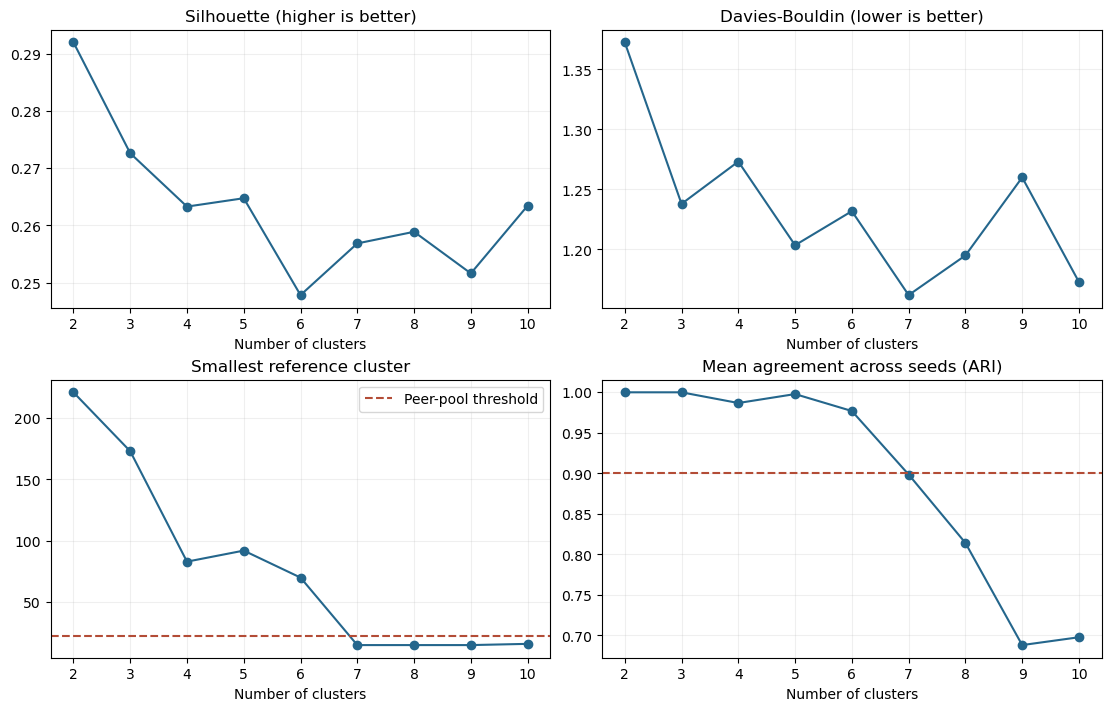

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
for ax, metric, title in zip(axes.flat,
    ["silhouette", "davies_bouldin", "min_cluster_size", "mean_seed_ari"],
    ["Silhouette (higher is better)", "Davies-Bouldin (lower is better)", "Smallest reference cluster", "Mean agreement across seeds (ARI)"],
):
    ax.plot(cluster_metrics_df["k"], cluster_metrics_df[metric], marker="o", color="#24668c")
    ax.set(title=title, xlabel="Number of clusters", xticks=cluster_metrics_df["k"])
    ax.grid(alpha=0.2)
axes[1, 0].axhline(MIN_REFERENCE_CLUSTER_SIZE, color="#b34c36", linestyle="--", label="Peer-pool threshold")
axes[1, 0].legend()
axes[1, 1].axhline(MIN_STABILITY_ARI, color="#b34c36", linestyle="--")
fig.savefig(OUTPUT_DIR / "3_cluster_count_diagnostics.png", dpi=160)
plt.show()


## 4 Select and interpret the final clusters

Choose a cluster count from the **current run's diagnostics**. With `REQUESTED_K=None`, select the highest silhouette among candidates that meet the peer-pool and stability requirements and the near-best silhouette preference. Ties favor lower Davies?Bouldin, then fewer clusters. If no feasible count is near the overall best silhouette, use the best feasible count and print that fallback explicitly. If no count has sufficient peers and stability, stop with an actionable error rather than relax those requirements silently.

Inspect the original-scale candidate profiles from section 3. A two-cluster choice can provide a broad county-context split; larger choices can distinguish finer age or digital-engagement patterns, while creating smaller peer pools. Set `REQUESTED_K` to a reviewed count if interpretation supports an alternative. A manual choice must still meet peer-pool and stability requirements; being outside the near-best silhouette preference is reported rather than triggering an assertion. A previously reviewed fixed count is not assumed to remain shortlisted when input data changes.

Inspect original-scale medians/ranges, school shares, geographic concentration, within-cluster silhouettes, and the nearest actual parishes to each centroid. The feature-separation table measures the share of each transformed feature's variance explained by cluster means. A feature can contribute little to these clusters even though it is included in distance calculations. The plots show centroid feature means and a two-dimensional PCA projection; PCA is for display only and is never used for clustering or ranking.


In [6]:
SELECTED_K, selection_reason = select_cluster_count(cluster_metrics_df, preferred_k=REQUESTED_K)
SELECTED_K = 5
selected_metrics = cluster_metrics_df.set_index("k").loc[SELECTED_K]
kmeans = candidate_models[SELECTED_K]
print(selection_reason)

assignments_df = parishes_df.copy()
for column in ["is_reference", "n_observed_features", "imputed_features"]:
    assignments_df[column] = input_quality_df[column]
assignments_df["assignment_quality"] = np.select(
    [reference_mask.to_numpy(), assignable_mask.to_numpy()],
    ["complete", "provisional_imputed"], default="unassigned_no_features",
)
assignments_df["cluster"] = pd.Series(pd.NA, index=assignments_df.index, dtype="Int64")
with threadpool_limits(limits=1):
    assignments_df.loc[assignable_mask, "cluster"] = kmeans.predict(model_matrix[assignable_mask.to_numpy()])
assignments_df["cluster"] = assignments_df["cluster"].astype("Int64")
assignments_df["distance_to_centroid"] = np.nan
assigned_labels = assignments_df.loc[assignable_mask, "cluster"].to_numpy(dtype=int)
assignments_df.loc[assignable_mask, "distance_to_centroid"] = np.linalg.norm(
    model_matrix[assignable_mask.to_numpy()] - kmeans.cluster_centers_[assigned_labels], axis=1,
)
assignments_df["cluster_silhouette"] = np.nan
with threadpool_limits(limits=1):
    reference_silhouettes = silhouette_samples(reference_matrix, kmeans.labels_)
assignments_df.loc[reference_mask, "cluster_silhouette"] = reference_silhouettes

cluster_profiles_df = cluster_profiles(reference_df, kmeans.labels_)
silhouette_by_cluster = pd.DataFrame({"cluster": kmeans.labels_, "silhouette": reference_silhouettes})
silhouette_summary = silhouette_by_cluster.groupby("cluster").agg(
    mean_silhouette=("silhouette", "mean"), negative_silhouette_share=("silhouette", lambda s: s.lt(0).mean()),
)
cluster_profiles_df = cluster_profiles_df.merge(silhouette_summary, on="cluster", validate="one_to_one")
cluster_profiles_df["n_target_reference"] = cluster_profiles_df["cluster"].map(
    assignments_df.loc[reference_mask & assignments_df["diocese"].eq(TARGET_DIOCESE)].groupby("cluster").size()
).fillna(0).astype(int)

# Use original units for interpretation and retain transformed centers for reproducibility.
cluster_profiles_df.to_csv(OUTPUT_DIR / "4_cluster_profiles.csv", index=False)
assignments_df.to_csv(OUTPUT_DIR / "4_parish_clusters.csv", index=False)
centroids_df = pd.DataFrame(kmeans.cluster_centers_, columns=MODEL_FEATURES).rename_axis("cluster")
centroids_df.to_csv(OUTPUT_DIR / "4_cluster_centroids.csv")
for column, filename in [("diocese", "4_cluster_dioceses.csv"), ("county_fips", "4_cluster_counties.csv")]:
    counts = assignments_df.loc[reference_mask].groupby(["cluster", column], dropna=False).size().rename("n_parishes").reset_index()
    counts.to_csv(OUTPUT_DIR / filename, index=False)

exemplars_df = assignments_df.loc[reference_mask].sort_values(
    ["cluster", "distance_to_centroid", "parish_index"], kind="stable",
).groupby("cluster", sort=False).head(3)
exemplars_df[["cluster", "parish_index", "name", "diocese", *FEATURES, "distance_to_centroid"]].to_csv(
    OUTPUT_DIR / "4_cluster_exemplars.csv", index=False,
)
feature_separation = []
for j, feature in enumerate(MODEL_FEATURES):
    total_ss = np.square(reference_matrix[:, j] - reference_matrix[:, j].mean()).sum()
    within_ss = np.square(reference_matrix[:, j] - kmeans.cluster_centers_[kmeans.labels_, j]).sum()
    feature_separation.append({"model_feature": feature, "explained_variance_fraction": 1 - within_ss / total_ss if total_ss else 0.0})
feature_separation_df = pd.DataFrame(feature_separation)
feature_separation_df.to_csv(OUTPUT_DIR / "4_feature_separation.csv", index=False)
cluster_profiles_df[[
    "cluster", "n_reference_parishes", "county_population_median", "county_median_age_median",
    "n_social_links_median", "school_share", "n_counties", "largest_diocese_share",
    "mean_silhouette", "negative_silhouette_share",
]].round(3)


Selected k=2 from current feasible candidates by highest silhouette; ties favor lower Davies-Bouldin, then fewer clusters. The selected count is in the near-best silhouette shortlist.


,cluster,n_reference_parishes,county_population_median,county_median_age_median,n_social_links_median,school_share,n_counties,largest_diocese_share,mean_silhouette,negative_silhouette_share
0,0,101,46095.0,41.8,3.0,0.416,61,0.386,0.229,0.069
1,1,128,353657.5,35.7,0.0,0.195,36,0.305,0.264,0.023
2,2,146,414809.0,40.4,2.0,0.274,22,0.260,0.279,0.000
3,3,92,37594.0,42.3,0.0,0.130,54,0.304,0.281,0.011
4,4,122,385410.0,35.0,4.0,0.467,30,0.221,0.265,0.016


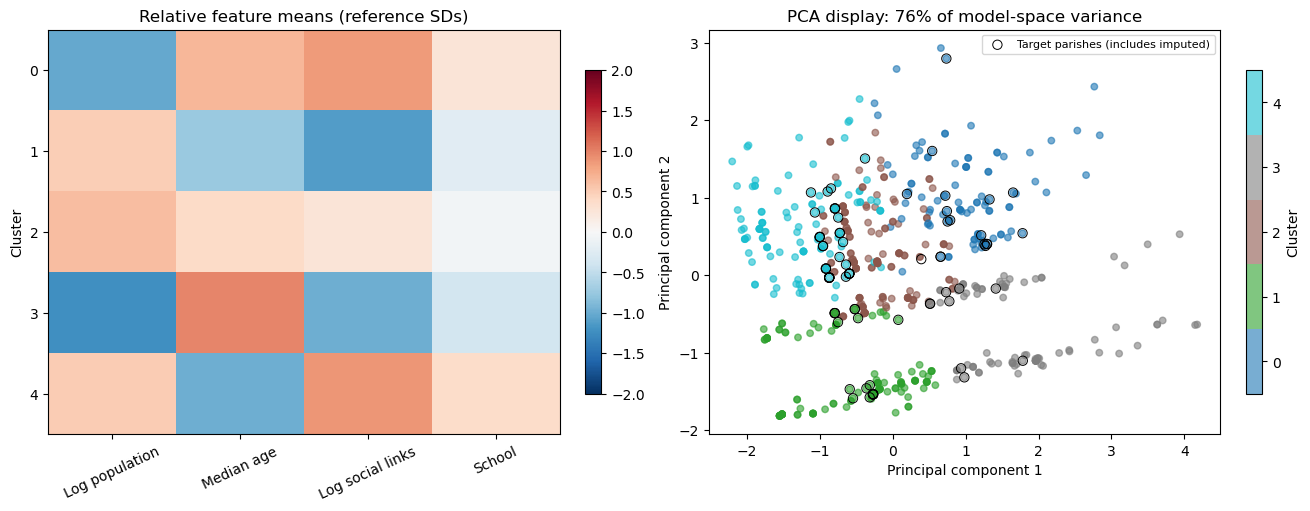

,model_feature,explained_variance_fraction
0,log_county_population,0.616
1,county_median_age,0.582
2,log_n_social_links,0.725
3,attached_school,0.072


In [7]:
with threadpool_limits(limits=1):
    pca = PCA(n_components=2).fit(reference_matrix)
    display_matrix = pca.transform(model_matrix)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
centroid_relative = (kmeans.cluster_centers_ - reference_matrix.mean(axis=0)) / np.where(reference_matrix.std(axis=0) > 0, reference_matrix.std(axis=0), 1)
image = axes[0].imshow(centroid_relative, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
axes[0].set(xticks=range(4), xticklabels=["Log population", "Median age", "Log social links", "School"], yticks=range(SELECTED_K), ylabel="Cluster", title="Relative feature means (reference SDs)")
axes[0].tick_params(axis="x", labelrotation=25)
fig.colorbar(image, ax=axes[0], shrink=0.8)
cluster_scatter = axes[1].scatter(display_matrix[reference_mask, 0], display_matrix[reference_mask, 1], c=kmeans.labels_, cmap=plt.get_cmap("tab10", SELECTED_K), s=22, alpha=0.6, vmin=-0.5, vmax=SELECTED_K - 0.5)
fig.colorbar(cluster_scatter, ax=axes[1], ticks=range(SELECTED_K), label="Cluster", shrink=0.8)
target_mask = assignments_df["diocese"].eq(TARGET_DIOCESE) & assignable_mask
axes[1].scatter(display_matrix[target_mask, 0], display_matrix[target_mask, 1], facecolors="none", edgecolors="black", s=45, linewidths=0.7, label="Target parishes (includes imputed)")
axes[1].set(title=f"PCA display: {pca.explained_variance_ratio_.sum():.0%} of model-space variance", xlabel="Principal component 1", ylabel="Principal component 2")
axes[1].legend(fontsize=8)
fig.savefig(OUTPUT_DIR / "4_cluster_interpretation.png", dpi=160)
plt.show()
feature_separation_df.round(3)


### Interpretation and practical limits

Use the current profile table to describe each selected group in original units: county population, county age, social-link count, and school share. For a two-cluster fit, inspect whether the broad split represents smaller/older versus larger/younger county contexts. For larger fits, inspect whether additional groups provide meaningful age or homepage-link differences. The printed selection reason and saved metrics identify the selected count for this run.

Check `negative_silhouette_share`, geographic concentration, and centroid exemplars for weak, mixed, or geographically narrow groups. School prevalence can vary within clusters; both target and peer features are included in the match CSV for individual screening. The feature-separation table indicates which attributes actually distinguish the groups. Multiple parishes share county measurements, and the profiles are parish-weighted, so counties contributing many parishes have more influence.

Neighbor rankings apply only inside the assigned cluster, so a close parish across a cluster boundary is excluded by design. Missing-target imputations can alter both cluster assignment and rank; treat those matches as provisional. Zero-distance ties indicate identical values on these four features. The run metadata reports the fraction of same-county pairs, zero-distance pairs, negative silhouettes, and feature separation from the current data, avoiding a stale interpretation from an earlier dataset.


## 5 Retrieve the ten nearest peers for every target parish

Use Euclidean distance in the exact four-dimensional model space used for KMeans, including target imputations. Candidate peers must be complete reference records **in the target's assigned cluster**, and the target itself is excluded by `parish_index`. Other parishes in the target diocese are eligible peers. Rank by ascending distance with `parish_index` as a deterministic tie-breaker. Preserve zero-distance ties and flag shared counties.

Save `5_target_nearest_matches.csv` with target/peer identities, feature values, cluster, rank, distance, and target assignment quality. Save `5_target_summary.csv` with one row for **every target parish**, including its cluster, imputed features, available peers, number of matches, and status. Return fewer than ten if a cluster lacks enough candidates; never pad with out-of-cluster parishes.



In [8]:
nearest_matches_df, target_summary_df = within_cluster_neighbors(
    assignments_df, model_matrix, target_diocese=TARGET_DIOCESE, top_n=TOP_N,
)
assert len(target_summary_df) == parishes_df["diocese"].eq(TARGET_DIOCESE).sum()
assert nearest_matches_df["target_parish_index"].ne(nearest_matches_df["peer_parish_index"]).all()
assert not nearest_matches_df.duplicated(["target_parish_index", "peer_parish_index"]).any()
for _, group in nearest_matches_df.groupby("target_parish_index", sort=False):
    assert group["distance"].is_monotonic_increasing
    assert group["rank"].tolist() == list(range(1, len(group) + 1))
nearest_matches_df.to_csv(OUTPUT_DIR / "5_target_nearest_matches.csv", index=False)
target_summary_df.to_csv(OUTPUT_DIR / "5_target_summary.csv", index=False)
print(f"Saved {len(nearest_matches_df)} ranked matches for {len(target_summary_df)} target parishes")
print(target_summary_df.groupby(["assignment_quality", "match_status"]).size().to_string())
nearest_matches_df[["target_name", "cluster", "rank", "peer_name", "peer_diocese", "distance", "target_assignment_quality"]].head(20)


Saved 800 ranked matches for 80 target parishes
assignment_quality   match_status
complete             ok              67
provisional_imputed  ok              13


,target_name,cluster,rank,peer_name,peer_diocese,distance,target_assignment_quality
0,Blessed Sacrament,3,1,St. Joseph Parish,Archdiocese of Mobile,0.156903,complete
1,Blessed Sacrament,3,2,San Felipe de Jesus,Diocese of Tucson,0.295241,complete
2,Blessed Sacrament,3,3,St. Francis Xavier,Diocese of Fort Wayne-South Bend,0.379594,complete
3,Blessed Sacrament,3,4,St. Martin de Porres,Diocese of Fort Wayne-South Bend,0.379594,complete
4,Blessed Sacrament,3,5,St. Paul the Apostle Parish,Archdiocese of Indianapolis,0.412926,complete
5,Blessed Sacrament,3,6,St. Elizabeth of Hungary Parish,Archdiocese of Indianapolis,0.639037,complete
6,Blessed Sacrament,3,7,St. John Bosco,Diocese of Fort Wayne-South Bend,0.728472,complete
7,Blessed Sacrament,3,8,Annunciation Parish,Archdiocese of Indianapolis,0.807872,complete
8,Blessed Sacrament,3,9,St. Anthony of Padua Parish,Archdiocese of Indianapolis,0.819474,complete
9,Blessed Sacrament,3,10,St. Charles Borromeo Parish,Archdiocese of Indianapolis,0.819474,complete


## 6 Save the fitted model and run metadata

Save the preprocessor and KMeans model for local reuse, along with input SHA-256, feature definitions/order, versions, seeds, selection thresholds, fit/reference counts, and selected metrics. The model artifact expects the transformed input produced by `prepare_clustering_data`: log population, median age, log social count, and numeric school. Apply the saved preprocessor to those columns before prediction. The saved matrices and assignment-quality flags allow auditing the exported neighbor distances.

Primary downstream files are `4_parish_clusters.csv`, `4_cluster_profiles.csv`, `5_target_nearest_matches.csv`, and `5_target_summary.csv`. Source feature data remains unchanged.


In [9]:
model_artifact = {
    "preprocessor": preprocessor, "kmeans": kmeans,
    "source_features": FEATURES, "transformed_input_columns": MODEL_FEATURES,
    "reference_parish_indices": reference_df["parish_index"].tolist(),
}
with (OUTPUT_DIR / "6_kmeans_model.pkl").open("wb") as file:
    pickle.dump(model_artifact, file, protocol=pickle.HIGHEST_PROTOCOL)
run_metadata = {
    "input_path": INPUT_PATH.as_posix(),
    "input_sha256": hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest(),
    "target_diocese": TARGET_DIOCESE, "top_n": TOP_N,
    "features": FEATURES, "model_features": MODEL_FEATURES,
    "transforms": {"county_population": "log1p then standardize", "county_median_age": "standardize", "n_social_links": "log1p then standardize", "attached_school": "0/1, no standardization"},
    "fit_population": "complete cases only; parish weighted",
    "missing_targets": "training continuous medians and school mode; provisional assignment",
    "candidate_peers": "complete reference members in the same cluster, excluding self",
    "selected_k": SELECTED_K, "tested_k": cluster_metrics_df["k"].tolist(),
    "seeds": SEEDS, "n_init": N_INIT,
    "minimum_reference_cluster_size": MIN_REFERENCE_CLUSTER_SIZE,
    "minimum_stability_ari": MIN_STABILITY_ARI, "silhouette_tolerance": SILHOUETTE_TOLERANCE,
    "selected_metrics": selected_metrics.to_dict(),
    "selection_reason": selection_reason,
    "requested_k": REQUESTED_K,
    "n_input_parishes": len(parishes_df), "n_reference_parishes": len(reference_df),
    "n_targets": len(target_summary_df), "n_matches": len(nearest_matches_df),
    "interpretation_diagnostics": {
        "feature_separation": feature_separation_df.to_dict("records"),
        "same_county_pair_share": float(nearest_matches_df["same_county"].mean()) if len(nearest_matches_df) else None,
        "zero_distance_pairs": int(nearest_matches_df["distance"].eq(0).sum()),
        "negative_reference_silhouette_share": float((assignments_df.loc[reference_mask, "cluster_silhouette"] < 0).mean()),
    },
    "n_provisional_targets": int(target_summary_df["assignment_quality"].eq("provisional_imputed").sum()),
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit_learn": sklearn.__version__},
}
(OUTPUT_DIR / "6_run_metadata.json").write_text(json.dumps(run_metadata, indent=2) + "\n", encoding="utf-8")
print(f"Saved outputs under {OUTPUT_DIR}")
target_summary_df[["target_parish_index", "target_name", "cluster", "assignment_quality", "n_matches", "match_status"]]


Saved outputs under data\05_cluster_parishes


,target_parish_index,target_name,cluster,assignment_quality,n_matches,match_status
0,784,Blessed Sacrament,3,complete,10,ok
1,785,Cathedral of the Immaculate Conception,4,complete,10,ok
2,786,Christ the King,4,provisional_imputed,10,ok
3,787,Corpus Christi,4,complete,10,ok
4,788,Holy Cross,4,complete,10,ok
...,...,...,...,...,...,...
75,859,St. Therese,4,complete,10,ok
76,860,"St. Thérèse, Little Flower",4,complete,10,ok
77,861,St. Thomas the Apostle,1,complete,10,ok
78,862,"St. Vincent de Paul, Elkhart",1,complete,10,ok
